# Data Audit: US Company Bankruptcy

## Data source

Lombardo et al. (2022), *Future Internet*, 14(8), 244. Downloaded from https://github.com/sowide/bankruptcy_dataset. Licence: CC BY 4.0.

Annual accounts of US companies listed on the NYSE and NASDAQ. A company is labelled "failed" if it filed for bankruptcy (Chapter 7 or 11) the year after its last year in the data. Company names are anonymised.

## Shape

In [1]:
import pandas as pd

train = pd.read_csv("../data/raw/financial_train.csv")
validation = pd.read_csv("../data/raw/financial_validation.csv")
test = pd.read_csv("../data/raw/financial_test.csv")

print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

Train: (3142, 57)
Validation: (233, 57)
Test: (2815, 57)


## What one row means

Each row is one company at the end of its last year in the data (`fyear`), with three years of accounts. The prediction is made once those accounts are available: will the company go bankrupt next year?

In [2]:
train.head()

,cik,fyear,status_label,3_current_assets,3_total_assets,3_cost_of_goods_sold,3_total_long_term_debt,3_depreciation_and_amortization,3_ebit,3_ebitda,...,1_inventory,1_total_current_liabilities,1_net_income,1_retained_earnings,1_total_receivables,1_total_revenue,1_market_value,1_total_liabilities,1_net_sales,1_total_operating_expenses
0,C1,2007,alive,581.502,1288.165,267.810,300.000,46.338,-5.522,40.816,...,92.741,665.257,133.769,-175.285,90.898,553.617,1541.7638,705.305,553.617,390.516
1,C2,2010,failed,6838.000,25088.000,18138.000,9253.000,995.000,308.000,1303.000,...,525.000,9374.000,-2071.000,-6638.000,811.000,23766.000,2976.3858,28110.000,23766.000,23256.000
2,C3,2006,alive,328.354,638.022,275.636,3.558,30.469,47.473,77.942,...,94.617,89.615,12.147,49.192,97.031,414.101,1060.6898,124.294,414.101,351.990
3,C4,2010,alive,9.513,26.228,18.932,5.700,0.337,-2.714,-2.377,...,1.063,3.571,-4.587,8.570,3.133,16.456,8.3439,26.106,16.456,19.761
4,C5,2001,alive,90.747,576.841,206.582,1.493,18.326,-26.051,-7.725,...,0.000,82.192,6.590,-20.463,61.133,278.188,633.7406,501.147,278.188,242.423


## Variable Types

In [3]:
print(train.dtypes.value_counts())
print()
print(train.dtypes.head(6))

float64    54
object      2
int64       1
dtype: int64

cik                      object
fyear                     int64
status_label             object
3_current_assets        float64
3_total_assets          float64
3_cost_of_goods_sold    float64
dtype: object


In [4]:
print("Missing values in train:", train.isna().sum().sum())
print("Missing values in validation:", validation.isna().sum().sum())
print("Missing values in test:", test.isna().sum().sum())

Missing values in train: 0
Missing values in validation: 0
Missing values in test: 0


In [5]:
print("Duplicate rows in train:", train.duplicated().sum())
print("Duplicate company codes in train:", train["cik"].duplicated().sum())
train_ids = set(train["cik"])
validation_ids = set(validation["cik"])
test_ids = set(test["cik"])

print("In train and validation:", len(train_ids & validation_ids))
print("In train and test:", len(train_ids & test_ids))
print("In validation and test:", len(validation_ids & test_ids))

Duplicate rows in train: 0
Duplicate company codes in train: 0
In train and validation: 0
In train and test: 0
In validation and test: 0


## Target Distribution

In [6]:
print("Train:", (train["status_label"] == "failed").sum(), "failed of", len(train))
print("Bankruptcy Rate:", round((train["status_label"] == "failed").mean() * 100, 1), "%")
print()
print("Validation:", (validation["status_label"] == "failed").sum(), "failed of", len(validation))
print("Bankruptcy Rate:", round((validation["status_label"] == "failed").mean() * 100, 1), "%")
print()
print("Test:", (test["status_label"] == "failed").sum(), "failed of", len(test))
print("Bankruptcy Rate:", round((test["status_label"] == "failed").mean() * 100, 1), "%")

Train: 403 failed of 3142
Bankruptcy Rate: 12.8 %

Validation: 27 failed of 233
Bankruptcy Rate: 11.6 %

Test: 72 failed of 2815
Bankruptcy Rate: 2.6 %


- The full CSV marks every year of a failed company as "failed", so the clean files are used instead.
- Companies that left the stock market for other reasons (e.g. takeovers) are labelled "alive".
- The test set is mostly 2018 companies that simply survived to the end of the data, which is why its bankruptcy rate is low.

## Outliers

In [7]:
columns = ["3_total_assets", "3_total_liabilities", "3_net_income", "3_net_sales", "3_market_value"]
train[columns].describe()

,3_total_assets,3_total_liabilities,3_net_income,3_net_sales,3_market_value
count,3142.000000,3142.000000,3142.000000,3142.000000,3142.000000
mean,957.981717,640.059176,7.756675,834.033456,924.597020
std,3298.330632,2361.333492,335.082143,3032.119776,3847.025995
min,0.001000,0.002000,-6469.000000,-0.143000,0.000700
25%,31.927000,15.237000,-15.554000,28.281500,12.820100
50%,123.185000,55.743500,-1.369000,118.452000,76.081850
75%,502.901250,293.628500,10.820250,463.310250,417.399325
max,56553.000000,33019.000000,4638.898000,70063.300000,87304.230000


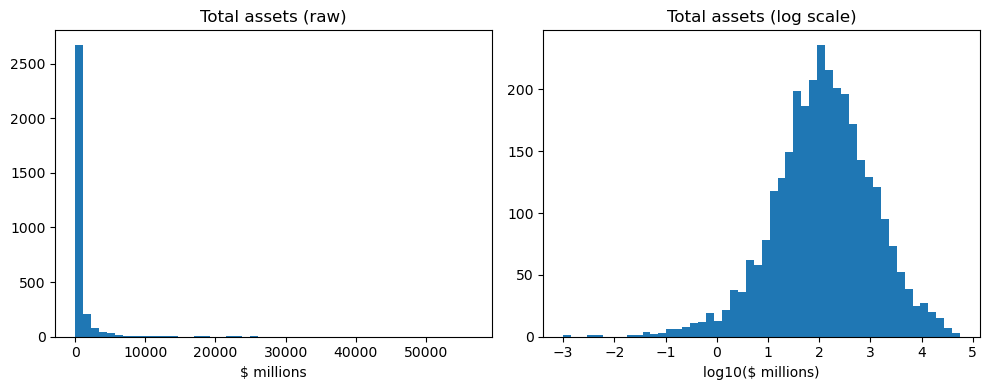

In [8]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(train["3_total_assets"], bins=50)
axes[0].set_title("Total assets (raw)")
axes[0].set_xlabel("$ millions")

axes[1].hist(np.log10(train["3_total_assets"]), bins=50)
axes[1].set_title("Total assets (log scale)")
axes[1].set_xlabel("log10($ millions)")

plt.tight_layout()
plt.show()

In [9]:
print("total_revenue identical to net_sales in all 3 years:",
      all((train[f"{y}_total_revenue"] == train[f"{y}_net_sales"]).all() for y in ["1", "2", "3"]))

print("Negative Net Sales:", (train["3_net_sales"] < 0).sum())
print("Total Assets under $1 million:", (train["3_total_assets"] < 1).sum())
print("Liabilities more than 5x assets:", (train["3_total_liabilities"] > 5 * train["3_total_assets"]).sum())
print("Current Assets greater than Total Assets:", (train["3_current_assets"] > train["3_total_assets"]).sum())

total_revenue identical to net_sales in all 3 years: True
Negative Net Sales: 2
Total Assets under $1 million: 80
Liabilities more than 5x assets: 77
Current Assets greater than Total Assets: 0


## Audit summary

**Data source.** The authors' clean files (`financial_train`, `financial_validation`, `financial_test`) were used rather than the full CSV. The full CSV labels every year of an eventually bankrupt company as "failed", and many values have no decimal point making them too large.

**Shape.** 6,190 companies in total (3,142 in train, 233 in validation and 2,815 in test), 57 columns each.

**Variable types.** 54 numeric accounting columns (float), the year `fyear` (integer), and two text columns: the company code `cik` and the label `status_label`. The company code is used only as an ID and `fyear` only for the time split.

**Missing values.** None in any of the three files.

**Duplicates.** No duplicate rows and no repeated company codes. The columns `total_revenue` and `net_sales` are identical in every row, so only `net_sales` is used.

**Target distribution.** The bankruptcy rate is 12.8% in train, 11.6% in validation and only 2.6% in test. The classes are imbalanced, so accuracy will not be the main metric.

**Outliers.** Company size is very skewed, most companies are small, but a few are huge. 2 companies have negative net sales which is unusual and is flagged. The model will use financial ratios instead of raw figures, and extreme values are clipped using limits from the training data.

## Leakage risks

| Risk | How it is avoided |
|---|---|
| Learning from the future | Split by year: train 2001–2014, validation 2015, test 2016–2018 |
| Same company in train and test | Each company appears once (checked: 0 overlap) |
| Preprocessing using test data | All scaling and clipping use limits worked out from training data only |
| Tuning on the test set | Test set only used once, at the end |